# PerfectPetClub — Task 3: Churn Classification with PySpark ML
**Module:** 7COM2005 Data Engineering | **Team:** P4G5 | **Notebook:** `notebooks/pyspark_ml.ipynb`

**Input:** `data/processed/processed_churn.parquet` (written by the ETL notebook). **Goal:** classify whether a customer cancels auto-renew (`churn = 1`).

### Approach
1. Load the Parquet file into a Spark DataFrame and inspect schema / class balance.
2. **Stratified 80/20 train-test split** (seeded, so results are reproducible).
3. Spark ML `Pipeline`: `StringIndexer` → `OneHotEncoder` → `VectorAssembler` → (`StandardScaler` for Logistic Regression) → classifier. Because the whole pipeline sits inside the cross-validator, encoders/scalers are **re-fitted on each training fold only** (no information leaks from the validation fold).
4. Three model families — **Logistic Regression, Random Forest, Gradient-Boosted Trees** — each tuned with `ParamGridBuilder` + 5-fold `CrossValidator` optimising **ROC-AUC**.
5. Evaluate on the untouched test set: confusion matrices, ROC and precision-recall curves, metric table with a bootstrap confidence interval, feature importance and a threshold analysis.

> **Reminder about the data:** the ETL deliberately removed leakage-prone columns (tenure, end date, recency). So **modest scores are expected and honest** — near-perfect scores would be a red flag.

## 0. Setup: imports, paths, Spark session

In [1]:
import os
import sys
import warnings
from pathlib import Path

# Make Spark workers use the same Python as this notebook (avoids "Python worker failed to connect" errors).
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
warnings.filterwarnings("ignore", message="PySpark does not yet fully support pandas")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve, average_precision_score)

from pyspark.ml import Pipeline
from pyspark.ml.classification import GBTClassifier, LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.sql import SparkSession
import pyspark.sql.functions as F

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
SEED = 42


def find_project_root(start=None) -> Path:
    here = Path(start or Path.cwd()).resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project root (folder containing data/).")


ROOT = find_project_root()
PARQUET_PATH = ROOT / "data" / "processed" / "processed_churn.parquet"
FIG_DIR = ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not PARQUET_PATH.exists():
    raise FileNotFoundError(f"{PARQUET_PATH} not found - run notebooks/etl_pipeline.ipynb first.")

spark = (SparkSession.builder.master("local[*]").appName("PerfectPetClub-Churn")
         .config("spark.sql.shuffle.partitions", "4")      # dataset is tiny: avoid 200 mostly-empty partitions
         .config("spark.driver.memory", "2g")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark {spark.version} | master={spark.sparkContext.master} | cores={spark.sparkContext.defaultParallelism}")

Picked up JAVA_TOOL_OPTIONS: -XX:+IgnoreUnrecognizedVMOptions -XX:-UseBASE64Intrinsics


Picked up JAVA_TOOL_OPTIONS: -XX:+IgnoreUnrecognizedVMOptions -XX:-UseBASE64Intrinsics


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/18 22:13:03 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/18 22:13:03 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/18 22:13:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.3.0 | master=local[*] | cores=1


## 1. Load the Parquet dataset and inspect it

In [2]:
df = spark.read.parquet(str(PARQUET_PATH))
print(f"rows={df.count()}  columns={len(df.columns)}")
df.printSchema()

rows=221  columns=33
root
 |-- customer_id: long (nullable = true)
 |-- churn: long (nullable = true)
 |-- plan: string (nullable = true)
 |-- preferred_gateway: string (nullable = true)
 |-- preferred_device: string (nullable = true)
 |-- preferred_crm_channel: string (nullable = true)
 |-- county: string (nullable = true)
 |-- orders_per_month: double (nullable = true)
 |-- spend_per_month: double (nullable = true)
 |-- avg_order_value: double (nullable = true)
 |-- std_order_value: double (nullable = true)
 |-- items_per_order: double (nullable = true)
 |-- avg_item_price: double (nullable = true)
 |-- order_trend: double (nullable = true)
 |-- share_directdebit: double (nullable = true)
 |-- delivery_late_rate: double (nullable = true)
 |-- avg_delivery_days: double (nullable = true)
 |-- delivery_missing_share: double (nullable = true)
 |-- avg_rating: double (nullable = true)
 |-- has_review: long (nullable = true)
 |-- reviews_per_order: double (nullable = true)
 |-- logins_per_

In [3]:
class_counts = df.groupBy("churn").count().orderBy("churn")
class_counts.show()
n_total = df.count()
majority_share = class_counts.agg(F.max("count")).first()[0] / n_total
print(f"Majority-class baseline accuracy: {majority_share:.3f}  (a model must beat this to be useful)")
print("Nulls per column:", {c: df.filter(F.col(c).isNull()).count() for c in df.columns if df.filter(F.col(c).isNull()).count() > 0} or "none")

+-----+-----+
|churn|count|
+-----+-----+
|    0|  135|
|    1|   86|
+-----+-----+



Majority-class baseline accuracy: 0.611  (a model must beat this to be useful)


Nulls per column: none


## 2. Choose features
* **Identifier** `customer_id` and the **target** `churn` are excluded from the features.
* **`county`** is excluded: ~40 categories for only 221 customers would just add noise/overfitting (and the data brief states no demographic patterns were built in).
* Remaining **categoricals** are indexed + one-hot encoded; all **numeric** columns are used as they are.

In [4]:
TARGET = "churn"
ID_COL = "customer_id"
CATEGORICAL = ["plan", "preferred_gateway", "preferred_device", "preferred_crm_channel"]
EXCLUDED = {ID_COL, TARGET, "county"}
NUMERIC = [c for c, t in df.dtypes if c not in EXCLUDED and c not in CATEGORICAL and t in ("int", "bigint", "double", "float")]
print(f"{len(NUMERIC)} numeric features: {NUMERIC}")
print(f"{len(CATEGORICAL)} categorical features: {CATEGORICAL}")
df = df.withColumn(TARGET, F.col(TARGET).cast("double"))

26 numeric features: ['orders_per_month', 'spend_per_month', 'avg_order_value', 'std_order_value', 'items_per_order', 'avg_item_price', 'order_trend', 'share_directdebit', 'delivery_late_rate', 'avg_delivery_days', 'delivery_missing_share', 'avg_rating', 'has_review', 'reviews_per_order', 'logins_per_month', 'share_mobile', 'share_tablet', 'share_desktop', 'login_trend', 'complaints_per_month', 'queries_per_month', 'complaint_share', 'nps_recommend', 'satisfaction_score', 'online_comparison_freq', 'income_midpoint']
4 categorical features: ['plan', 'preferred_gateway', 'preferred_device', 'preferred_crm_channel']


## 3. Stratified 80 / 20 train-test split
Within each class, customers are put in a seeded random order and the first 80% (by `percent_rank`) go to training. Unlike `sampleBy` (a random Bernoulli sample whose size varies), this gives an **exact** 80/20 split with the same churn rate in both parts. The test set is touched **only once**, at the very end.

In [5]:
from pyspark.sql import Window

by_class_random_order = Window.partitionBy(TARGET).orderBy(F.rand(SEED))
ranked = df.withColumn("_rank", F.percent_rank().over(by_class_random_order))
train = ranked.filter(F.col("_rank") < 0.8).drop("_rank").cache()
train.count()                                                                   # materialise the cache before building test
test = df.join(train.select(ID_COL), on=ID_COL, how="left_anti").cache()      # everything not in train
for name, part in [("train", train), ("test", test)]:
    n, pos = part.count(), part.filter(F.col(TARGET) == 1).count()
    print(f"{name:5s}: {n:4d} rows | churn rate {pos / n:.1%}")
assert train.join(test, ID_COL).count() == 0, "train/test overlap!"
print("No overlap between train and test sets.")

train:  176 rows | churn rate 38.6%


test :   45 rows | churn rate 40.0%


No overlap between train and test sets.


## 4. Pre-processing stages and the model pipelines
* `StringIndexer(handleInvalid="keep")` → numeric category index (unseen categories at prediction time won't crash).
* `OneHotEncoder` → sparse binary columns.
* `VectorAssembler` → one `features_raw` vector (numeric + one-hot).
* `StandardScaler` → `features_scaled` (z-score). Needed for **Logistic Regression** (regularisation penalises coefficients, so features must share a scale). Trees are scale-invariant and use `features_raw`.

In [6]:
def build_preprocessing_stages():
    indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CATEGORICAL]
    encoder = OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEGORICAL],
                            outputCols=[f"{c}_ohe" for c in CATEGORICAL], handleInvalid="keep")
    assembler = VectorAssembler(inputCols=NUMERIC + [f"{c}_ohe" for c in CATEGORICAL],
                                outputCol="features_raw", handleInvalid="error")
    return [*indexers, encoder, assembler]


scaler = StandardScaler(inputCol="features_raw", outputCol="features_scaled", withMean=True, withStd=True)

lr = LogisticRegression(featuresCol="features_scaled", labelCol=TARGET, maxIter=200)
rf = RandomForestClassifier(featuresCol="features_raw", labelCol=TARGET, seed=SEED)
gbt = GBTClassifier(featuresCol="features_raw", labelCol=TARGET, seed=SEED)

pipelines = {
    "Logistic Regression": Pipeline(stages=[*build_preprocessing_stages(), scaler, lr]),
    "Random Forest": Pipeline(stages=[*build_preprocessing_stages(), rf]),
    "Gradient-Boosted Trees": Pipeline(stages=[*build_preprocessing_stages(), gbt]),
}
print({name: [type(s).__name__ for s in p.getStages()][-2:] for name, p in pipelines.items()})

{'Logistic Regression': ['StandardScaler', 'LogisticRegression'], 'Random Forest': ['VectorAssembler', 'RandomForestClassifier'], 'Gradient-Boosted Trees': ['VectorAssembler', 'GBTClassifier']}


## 5. Hyper-parameter tuning with `ParamGridBuilder` + 5-fold `CrossValidator`
| Model | Parameters tuned | What they do |
|---|---|---|
| Logistic Regression | `regParam` (0.001–1), `elasticNetParam` (0 = L2/ridge, 1 = L1/lasso) | strength and type of regularisation — fights overfitting on only ~176 training rows |
| Random Forest | `numTrees`, `maxDepth`, `minInstancesPerNode` | number of trees (variance ↓), tree complexity, leaf size (smoothing) |
| GBT | `maxDepth`, `maxIter`, `stepSize` | tree complexity, number of boosting rounds, learning rate |

The metric optimised is **ROC-AUC**: it is threshold-independent and robust to the mild class imbalance (39% churn). Folds are random (Spark's `CrossValidator` is not stratified) with a fixed seed.

In [7]:
param_grids = {
    "Logistic Regression": (ParamGridBuilder()
                            .addGrid(lr.regParam, [0.001, 0.01, 0.1, 1.0])
                            .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0]).build()),
    "Random Forest": (ParamGridBuilder()
                      .addGrid(rf.numTrees, [50, 100])
                      .addGrid(rf.maxDepth, [3, 5])
                      .addGrid(rf.minInstancesPerNode, [1, 3]).build()),
    "Gradient-Boosted Trees": (ParamGridBuilder()
                               .addGrid(gbt.maxDepth, [2, 4])
                               .addGrid(gbt.maxIter, [20, 40])
                               .addGrid(gbt.stepSize, [0.05, 0.1]).build()),
}
auc_evaluator = BinaryClassificationEvaluator(labelCol=TARGET, rawPredictionCol="rawPrediction", metricName="areaUnderROC")
for name, grid in param_grids.items():
    print(f"{name:24s} {len(grid):2d} combinations x 5 folds = {len(grid) * 5} fits")

Logistic Regression      12 combinations x 5 folds = 60 fits
Random Forest             8 combinations x 5 folds = 40 fits
Gradient-Boosted Trees    8 combinations x 5 folds = 40 fits


In [8]:
import time

cv_models = {}
for name, pipe in pipelines.items():
    t0 = time.time()
    cv = CrossValidator(estimator=pipe, estimatorParamMaps=param_grids[name], evaluator=auc_evaluator,
                        numFolds=5, seed=SEED, parallelism=2)
    cv_models[name] = cv.fit(train)
    best_idx = int(np.argmax(cv_models[name].avgMetrics))
    print(f"{name:24s} best CV AUC = {cv_models[name].avgMetrics[best_idx]:.3f} "
          f"(+/- {cv_models[name].stdMetrics[best_idx]:.3f})  [{time.time() - t0:5.1f}s]")

Logistic Regression      best CV AUC = 0.677 (+/- 0.073)  [419.1s]


Random Forest            best CV AUC = 0.683 (+/- 0.079)  [ 72.7s]


Gradient-Boosted Trees   best CV AUC = 0.655 (+/- 0.131)  [234.4s]


### 5.1 Best hyper-parameters per model

In [9]:
def best_params(cv_model):
    best_idx = int(np.argmax(cv_model.avgMetrics))
    grid = cv_model.getEstimatorParamMaps()[best_idx]
    return {p.name: v for p, v in grid.items()}


tuning_summary = pd.DataFrame([
    {"model": name, "best_cv_auc": max(m.avgMetrics), "cv_auc_std": m.stdMetrics[int(np.argmax(m.avgMetrics))],
     "worst_config_cv_auc": min(m.avgMetrics), "best_params": best_params(m)}
    for name, m in cv_models.items()]).set_index("model")
tuning_summary

,best_cv_auc,cv_auc_std,worst_config_cv_auc,best_params
model,,,,
Logistic Regression,0.677244,0.072805,0.500000,"{'regParam': 0.01, 'elasticNetParam': 1.0}"
Random Forest,0.682953,0.078918,0.643439,"{'numTrees': 50, 'maxDepth': 5, 'minInstancesP..."
Gradient-Boosted Trees,0.654903,0.131291,0.607374,"{'maxDepth': 2, 'maxIter': 40, 'stepSize': 0.1}"


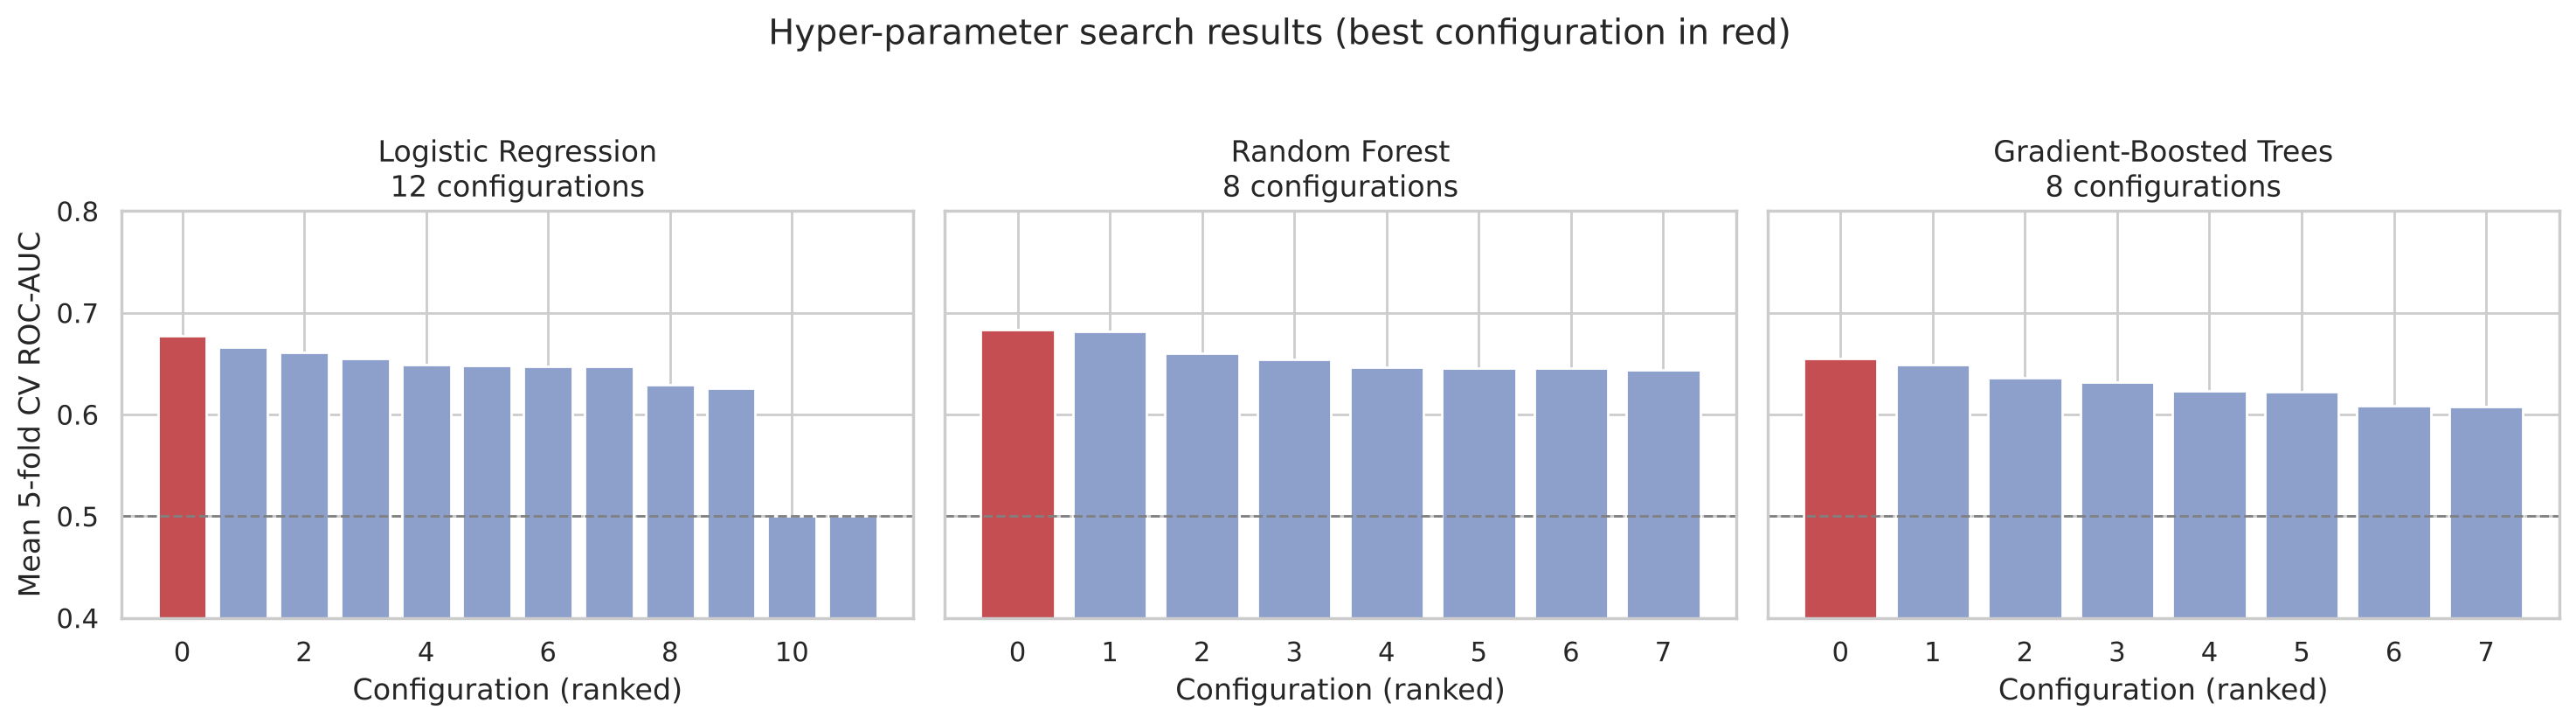

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, m) in zip(axes, cv_models.items()):
    scores = np.array(m.avgMetrics)
    order = np.argsort(scores)[::-1]
    colors = ["#c44e52" if i == 0 else "#8da0cb" for i in range(len(order))]
    ax.bar(range(len(order)), scores[order], color=colors)
    ax.axhline(0.5, color="grey", ls="--", lw=1)
    ax.set_title(f"{name}\n{len(order)} configurations"); ax.set_xlabel("Configuration (ranked)")
    ax.set_ylim(0.4, max(0.8, scores.max() + 0.05))
axes[0].set_ylabel("Mean 5-fold CV ROC-AUC")
fig.suptitle("Hyper-parameter search results (best configuration in red)", y=1.03)
fig.tight_layout(); fig.savefig(FIG_DIR / "06_hyperparameter_tuning.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Evaluate on the held-out test set
Predictions are collected into a small pandas DataFrame (44-ish rows) using `collect()` (rather than `toPandas()`, which is fragile across pandas/PySpark versions). Threshold metrics use the default decision threshold of 0.5; ROC-AUC and PR-AUC use the predicted probability.

In [11]:
def collect_predictions(model, data) -> pd.DataFrame:
    """Score a Spark DataFrame and return label / predicted class / P(churn) as a pandas DataFrame."""
    scored = (model.transform(data)
              .select(ID_COL, F.col(TARGET).alias("label"), F.col("prediction"),
                      vector_to_array("probability")[1].alias("p_churn")))
    rows = scored.collect()
    return pd.DataFrame([r.asDict() for r in rows])


predictions = {name: collect_predictions(m.bestModel, test) for name, m in cv_models.items()}
y_true = predictions["Logistic Regression"]["label"].astype(int).to_numpy()
print({name: p.shape for name, p in predictions.items()})
predictions["Random Forest"].head()

{'Logistic Regression': (45, 4), 'Random Forest': (45, 4), 'Gradient-Boosted Trees': (45, 4)}


,customer_id,label,prediction,p_churn
0,3,0.0,0.0,0.340889
1,7,1.0,0.0,0.464989
2,9,1.0,0.0,0.405224
3,10,0.0,0.0,0.449210
4,14,1.0,0.0,0.288616


In [12]:
rng = np.random.default_rng(SEED)


def bootstrap_auc_ci(y, p, n_boot=1000):
    """95% percentile bootstrap confidence interval for ROC-AUC (test set is small, so uncertainty matters)."""
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        stats.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(stats, [2.5, 97.5])


rows = []
for name, pred in predictions.items():
    y = pred["label"].astype(int).to_numpy(); yhat = pred["prediction"].astype(int).to_numpy(); p = pred["p_churn"].to_numpy()
    lo, hi = bootstrap_auc_ci(y, p)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
                 "recall": recall_score(y, yhat), "f1": f1_score(y, yhat),
                 "roc_auc": roc_auc_score(y, p), "roc_auc_95ci": f"[{lo:.2f}, {hi:.2f}]",
                 "pr_auc": average_precision_score(y, p),
                 "cv_auc_(train)": tuning_summary.loc[name, "best_cv_auc"]})
metrics = pd.DataFrame(rows).set_index("model")
baseline_acc = max(y_true.mean(), 1 - y_true.mean())
print(f"Test set: n={len(y_true)}, churn rate={y_true.mean():.1%}, majority-class baseline accuracy={baseline_acc:.3f}\n")
metrics.round(3)

Test set: n=45, churn rate=40.0%, majority-class baseline accuracy=0.600



,accuracy,precision,recall,f1,roc_auc,roc_auc_95ci,pr_auc,cv_auc_(train)
model,,,,,,,,
Logistic Regression,0.622,0.538,0.389,0.452,0.599,"[0.42, 0.77]",0.577,0.677
Random Forest,0.600,0.500,0.222,0.308,0.617,"[0.44, 0.78]",0.545,0.683
Gradient-Boosted Trees,0.622,0.529,0.500,0.514,0.656,"[0.48, 0.81]",0.621,0.655


In [13]:
# Cross-check our sklearn ROC-AUC against Spark's own evaluator on the same predictions (sanity check).
for name, m in cv_models.items():
    spark_auc = auc_evaluator.evaluate(m.bestModel.transform(test))
    assert abs(spark_auc - metrics.loc[name, "roc_auc"]) < 1e-6, (name, spark_auc, metrics.loc[name, "roc_auc"])
print("sklearn and Spark ROC-AUC agree for all models.")

sklearn and Spark ROC-AUC agree for all models.


In [14]:
# Automatic reading of the results: does each model's test ROC-AUC confidence interval exclude chance (0.5)?
for name, row in metrics.iterrows():
    lo, hi = (float(x) for x in row["roc_auc_95ci"].strip("[]").split(","))
    verdict = "significantly better than chance" if lo > 0.5 else "NOT distinguishable from chance (CI includes 0.5)"
    print(f"{name:24s} test AUC={row['roc_auc']:.2f}  95% CI [{lo:.2f}, {hi:.2f}]  -> {verdict}")

Logistic Regression      test AUC=0.60  95% CI [0.42, 0.77]  -> NOT distinguishable from chance (CI includes 0.5)
Random Forest            test AUC=0.62  95% CI [0.44, 0.78]  -> NOT distinguishable from chance (CI includes 0.5)
Gradient-Boosted Trees   test AUC=0.66  95% CI [0.48, 0.81]  -> NOT distinguishable from chance (CI includes 0.5)


### 6.1 Confusion matrices

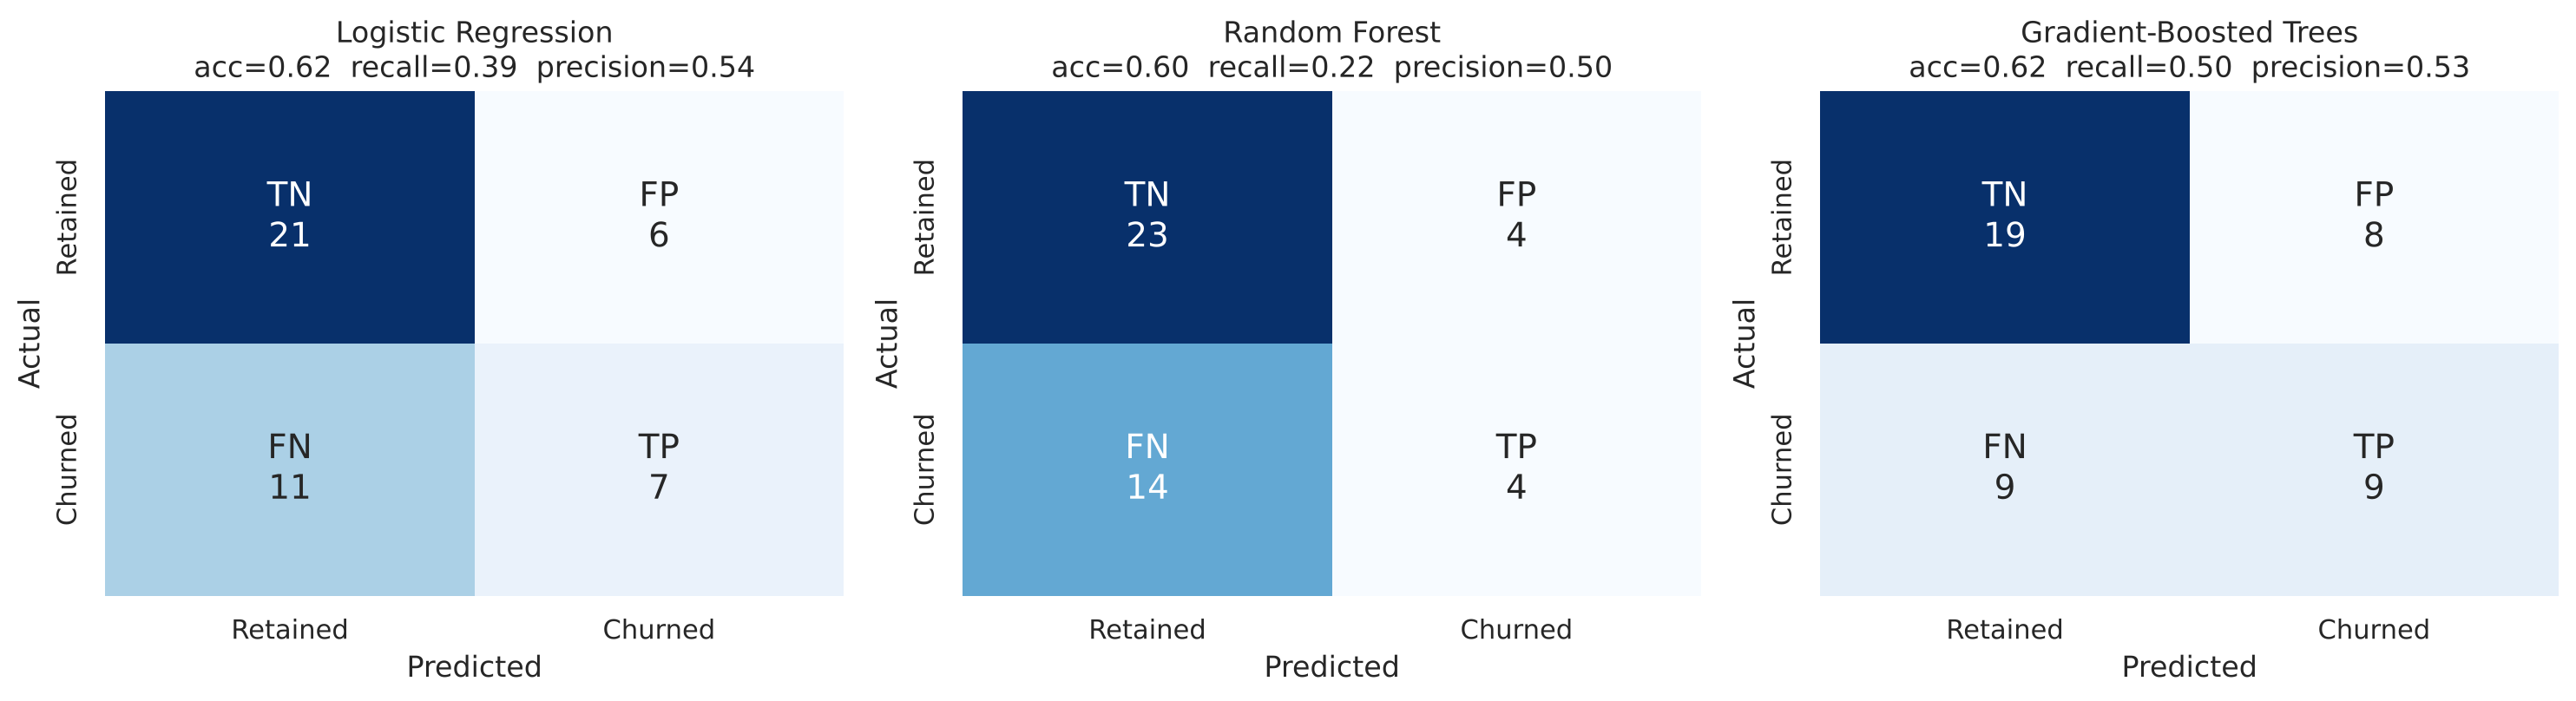

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(pred["label"].astype(int), pred["prediction"].astype(int), labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    annot = np.array([[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"])
    ax.set_title(f"{name}\nacc={(tp + tn) / cm.sum():.2f}  recall={tp / max(tp + fn, 1):.2f}  precision={tp / max(tp + fp, 1):.2f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
fig.tight_layout(); fig.savefig(FIG_DIR / "07_confusion_matrices.png", dpi=150); plt.show()

### 6.2 ROC and Precision-Recall curves

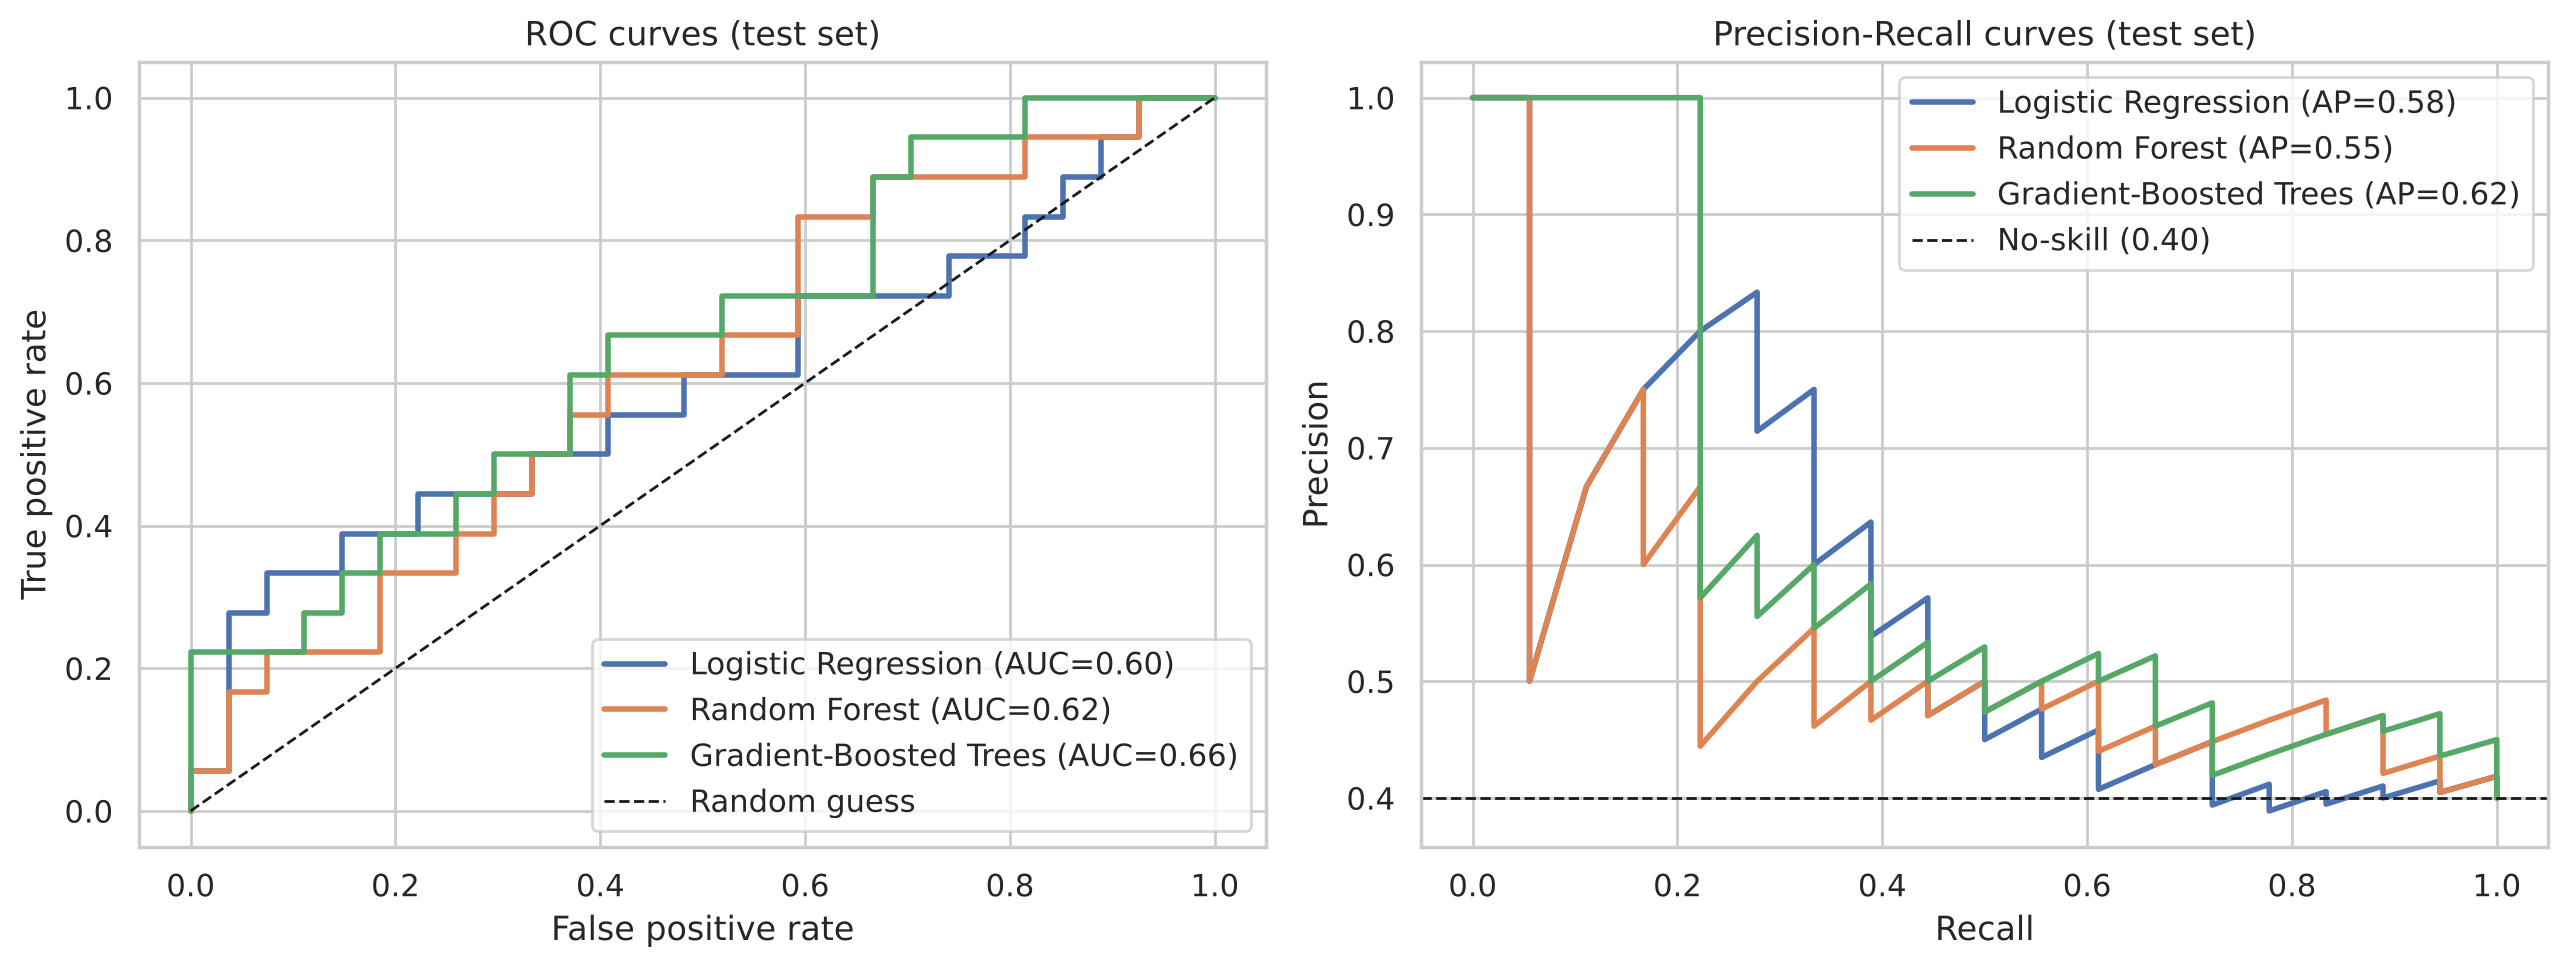

In [16]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5))
for name, pred in predictions.items():
    y = pred["label"].astype(int); p = pred["p_churn"]
    fpr, tpr, _ = roc_curve(y, p); prec, rec, _ = precision_recall_curve(y, p)
    ax_roc.plot(fpr, tpr, lw=2, label=f"{name} (AUC={auc(fpr, tpr):.2f})")
    ax_pr.plot(rec, prec, lw=2, label=f"{name} (AP={average_precision_score(y, p):.2f})")
ax_roc.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test set)")
ax_pr.axhline(y_true.mean(), color="k", ls="--", lw=1, label=f"No-skill ({y_true.mean():.2f})")
ax_pr.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves (test set)")
ax_roc.legend(loc="lower right"); ax_pr.legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "08_roc_and_pr_curves.png", dpi=150); plt.show()

### 6.3 Model comparison

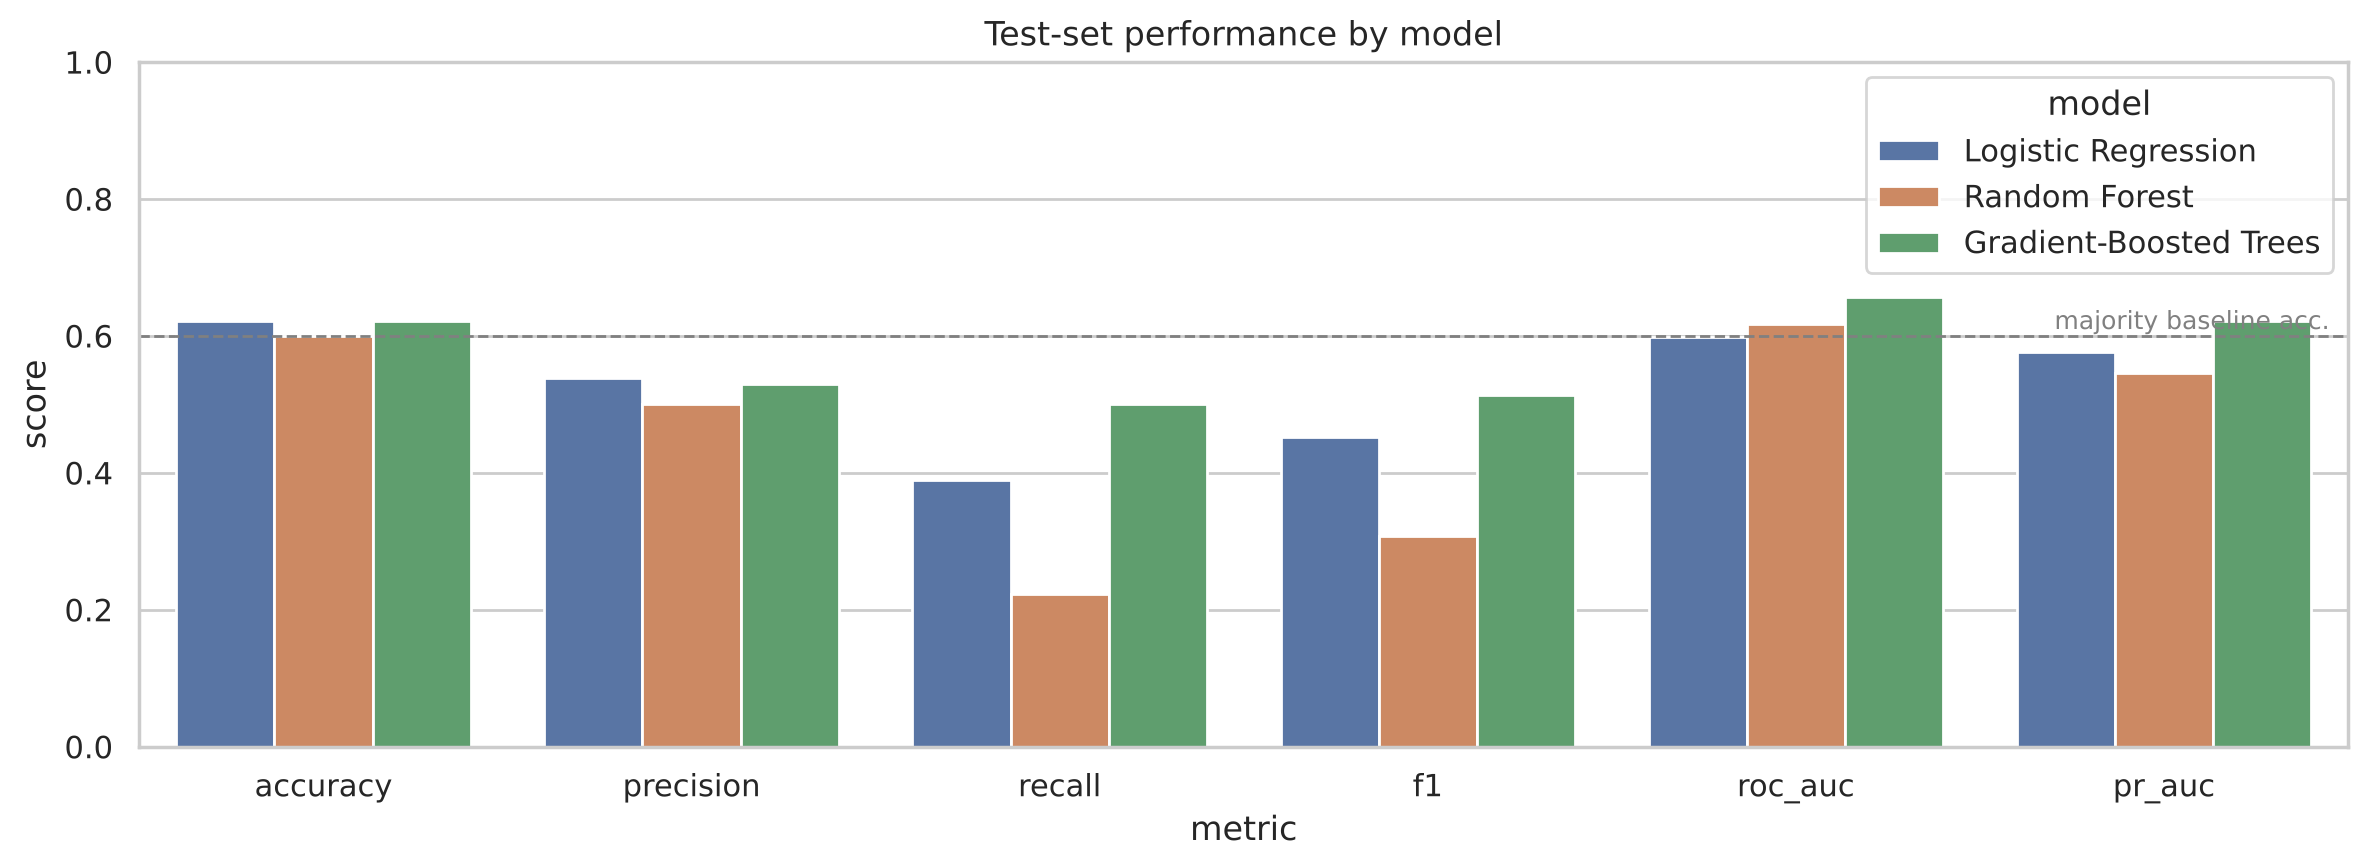

In [17]:
plot_df = metrics[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].reset_index().melt(id_vars="model", var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.barplot(data=plot_df, x="metric", y="score", hue="model", ax=ax)
ax.axhline(baseline_acc, color="grey", ls="--", lw=1); ax.text(5.45, baseline_acc + 0.01, "majority baseline acc.", ha="right", color="grey", fontsize=9)
ax.set_ylim(0, 1); ax.set_title("Test-set performance by model")
fig.tight_layout(); fig.savefig(FIG_DIR / "09_model_comparison.png", dpi=150); plt.show()

## 7. Selecting the best model and explaining it
We choose the model with the highest **cross-validated** AUC on the training data (not the test set — picking by test score would leak the test set into model selection).

In [18]:
best_name = tuning_summary["best_cv_auc"].idxmax()
best_model = cv_models[best_name].bestModel
print(f"Best model by cross-validated AUC: {best_name}")
print("Best hyper-parameters:", tuning_summary.loc[best_name, "best_params"])
print("Test metrics:"); metrics.loc[[best_name]].round(3).T

Best model by cross-validated AUC: Random Forest
Best hyper-parameters: {'numTrees': 50, 'maxDepth': 5, 'minInstancesPerNode': 3}
Test metrics:


model,Random Forest
accuracy,0.6
precision,0.5
recall,0.222
f1,0.308
roc_auc,0.617
roc_auc_95ci,"[0.44, 0.78]"
pr_auc,0.545
cv_auc_(train),0.683


43 model input columns (after one-hot encoding)


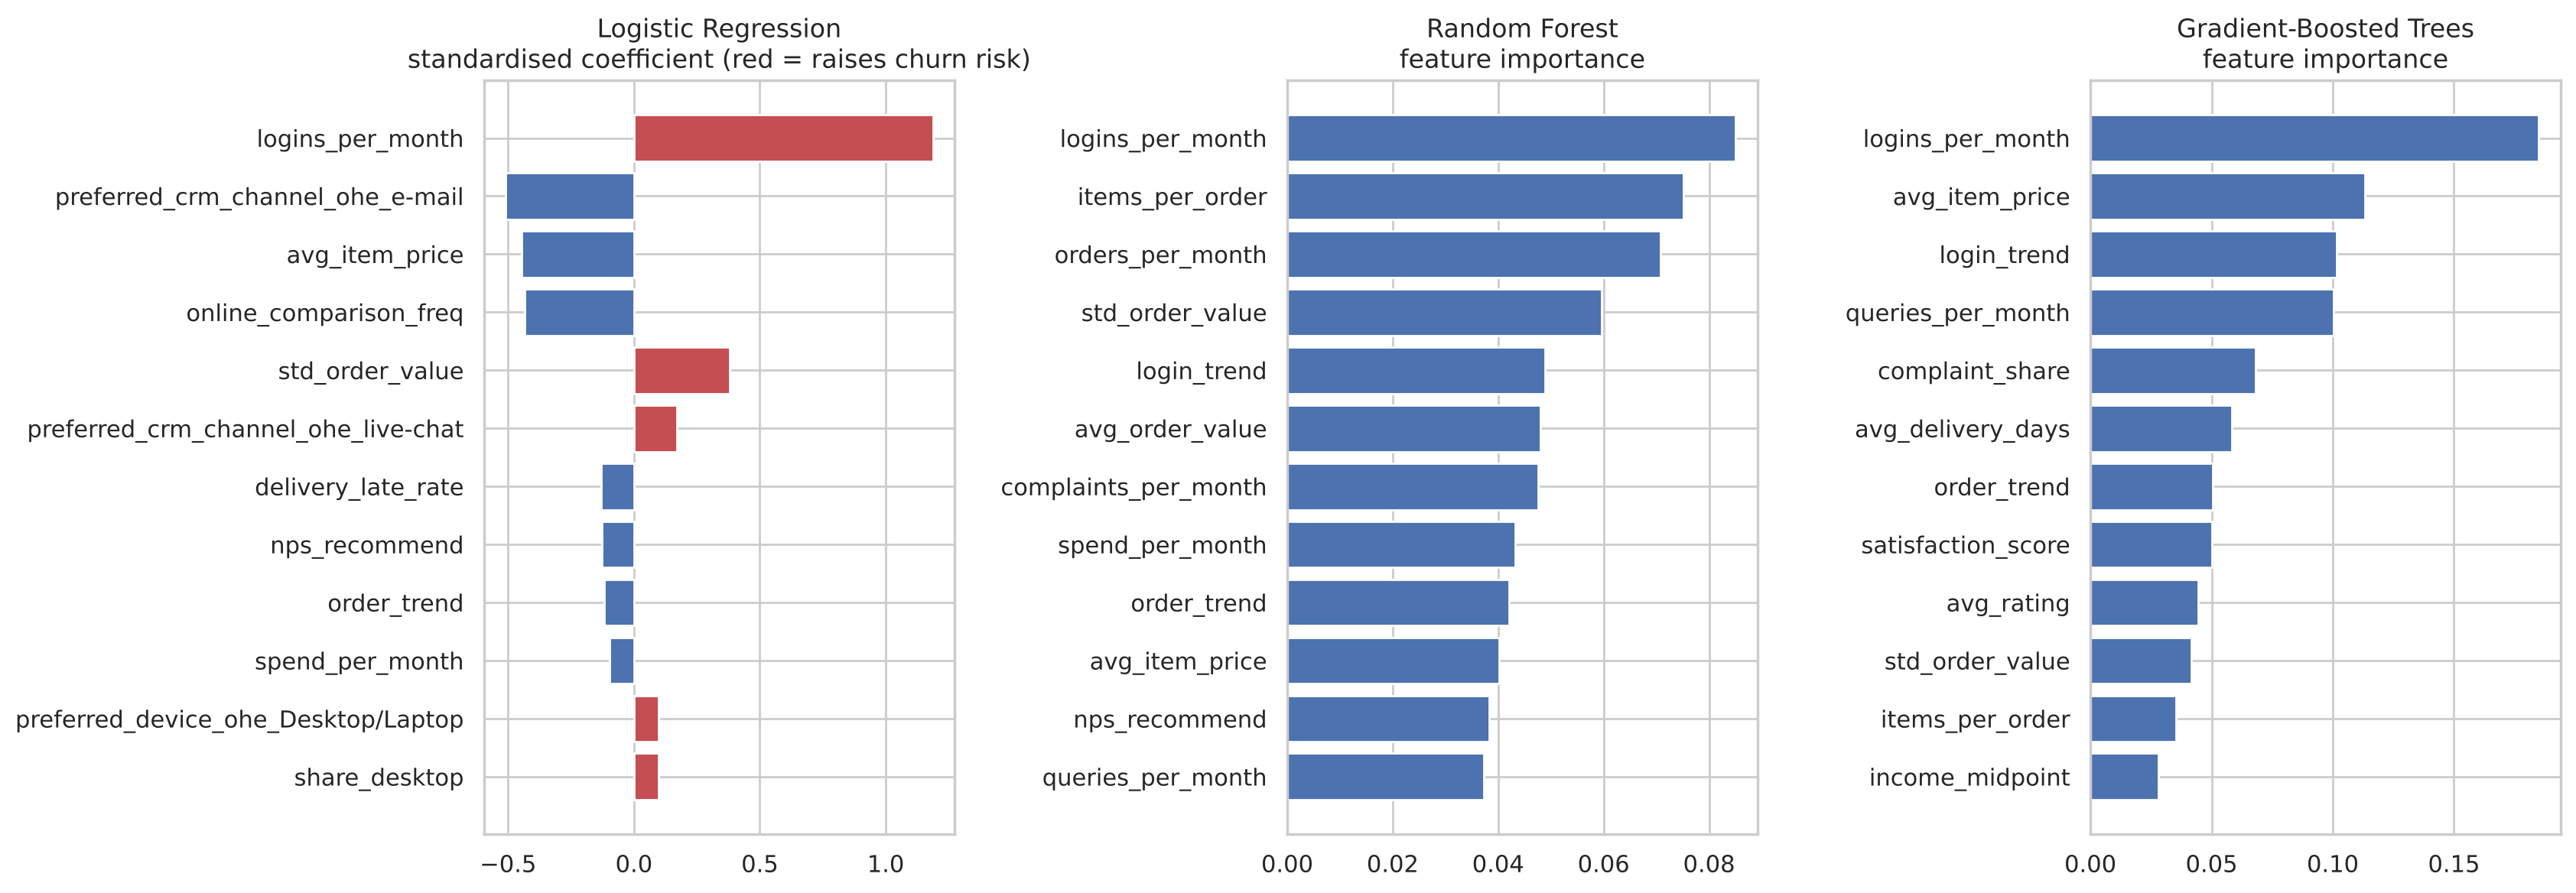

In [19]:
# Feature names, in vector order, come from the metadata that VectorAssembler attaches to 'features_raw'.
meta = best_model.transform(test).schema["features_raw"].metadata["ml_attr"]["attrs"]
feature_names = [a["name"] for a in sorted([x for grp in meta.values() for x in grp], key=lambda a: a["idx"])]
print(f"{len(feature_names)} model input columns (after one-hot encoding)")


def importance_frame(name, model):
    stage = model.stages[-1]
    if name == "Logistic Regression":
        vals = stage.coefficients.toArray()          # standardised coefficients (features were z-scored)
        return pd.DataFrame({"feature": feature_names, "value": vals}).assign(abs_value=lambda d: d["value"].abs())
    vals = stage.featureImportances.toArray()        # impurity-based importance
    return pd.DataFrame({"feature": feature_names, "value": vals}).assign(abs_value=lambda d: d["value"].abs())


fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, (name, m) in zip(axes, cv_models.items()):
    imp = importance_frame(name, m.bestModel).sort_values("abs_value", ascending=False).head(12).iloc[::-1]
    colors = ("#4c72b0" if name != "Logistic Regression" else None)
    if name == "Logistic Regression":
        colors = np.where(imp["value"] > 0, "#c44e52", "#4c72b0")
    ax.barh(imp["feature"], imp["value"], color=colors)
    ax.set_title(f"{name}\n" + ("standardised coefficient (red = raises churn risk)" if name == "Logistic Regression" else "feature importance"))
fig.tight_layout(); fig.savefig(FIG_DIR / "10_feature_importance.png", dpi=150); plt.show()

### 7.1 Threshold analysis (business trade-off)
The default threshold of 0.5 is not necessarily the best business choice. A **false negative** (missing a customer who will cancel) loses their revenue; a **false positive** (flagging a loyal customer) costs a retention offer. Lowering the threshold raises recall (catch more churners) at the cost of precision.

> **Caveat:** this analysis is *illustrative*. Choosing the threshold that maximises the **test** score would leak the test set into model selection; in practice the threshold would be chosen on cross-validated predictions or a separate validation set.

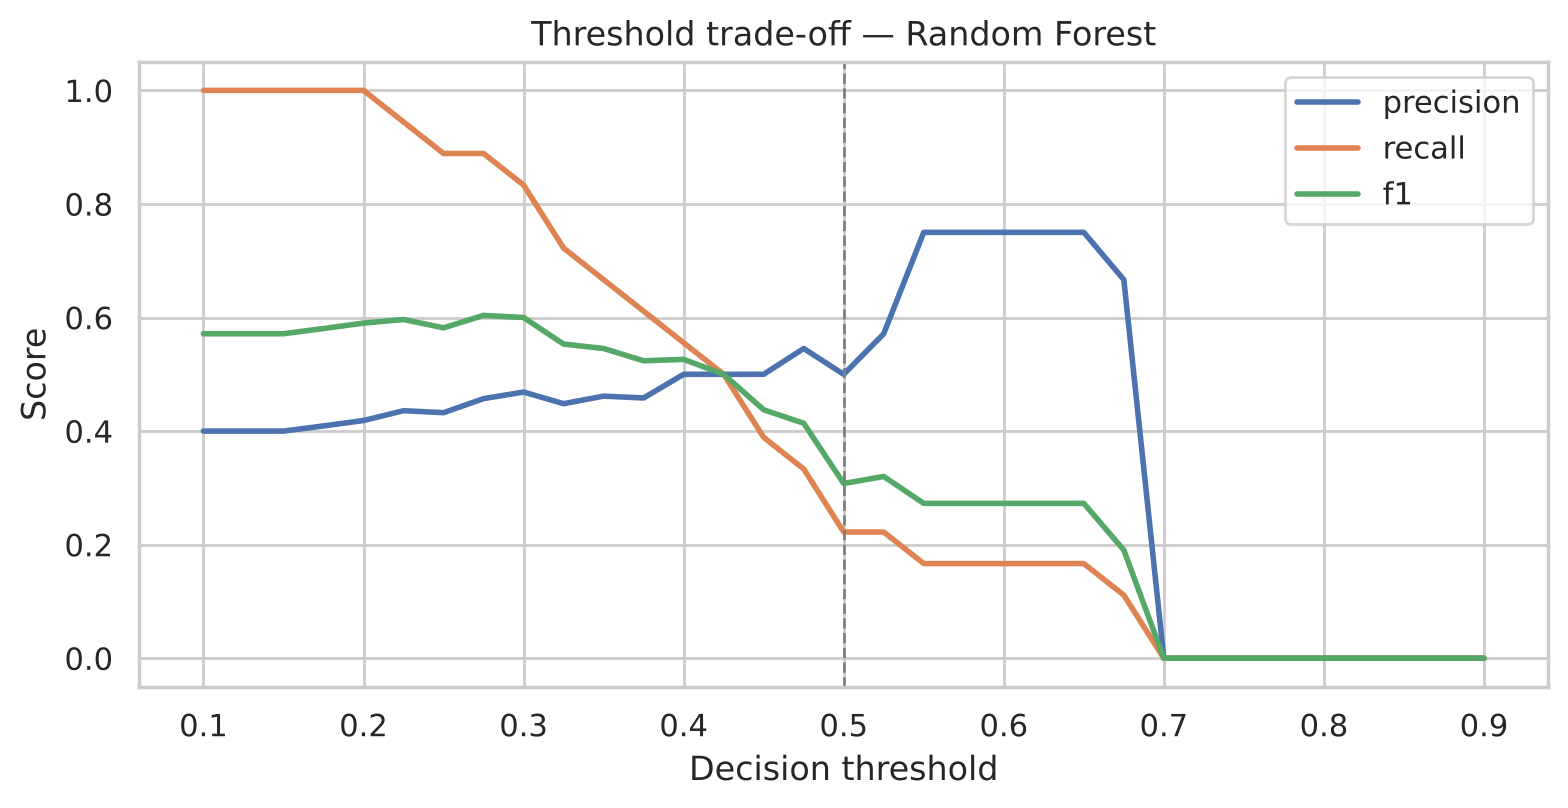

(Illustrative) threshold with the highest test F1: 0.28 (F1=0.60)
Predicted probabilities for Random Forest range from 0.17 to 0.69 - narrow, which is why the default 0.5 threshold finds few churners.


In [20]:
best_pred = predictions[best_name]
thresholds = np.linspace(0.1, 0.9, 33)
rows = []
for t in thresholds:
    yhat = (best_pred["p_churn"] >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(best_pred["label"], yhat, zero_division=0),
                 "recall": recall_score(best_pred["label"], yhat), "f1": f1_score(best_pred["label"], yhat)})
thr = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4.2))
for col in ["precision", "recall", "f1"]:
    ax.plot(thr["threshold"], thr[col], lw=2, label=col)
ax.axvline(0.5, color="grey", ls="--", lw=1); ax.set(xlabel="Decision threshold", ylabel="Score", title=f"Threshold trade-off — {best_name}")
ax.legend(); fig.tight_layout(); fig.savefig(FIG_DIR / "11_threshold_analysis.png", dpi=150); plt.show()
print(f"(Illustrative) threshold with the highest test F1: {thr.loc[thr['f1'].idxmax(), 'threshold']:.2f} (F1={thr['f1'].max():.2f})")
print(f"Predicted probabilities for {best_name} range from {best_pred['p_churn'].min():.2f} to {best_pred['p_churn'].max():.2f} - "
      "narrow, which is why the default 0.5 threshold finds few churners.")

## 8. Save metrics and shut down Spark

In [21]:
out_csv = ROOT / "outputs" / "model_metrics.csv"
metrics.round(4).to_csv(out_csv)
print(f"Saved {out_csv.relative_to(ROOT)}")
spark.stop()

Saved outputs/model_metrics.csv


## 9. Discussion: results, assumptions, limitations, improvements

**Reading the results.** With leakage-prone variables removed, the models achieve only modest discrimination (cross-validated AUC roughly 0.6–0.7; see the table and the automatic verdict in section 6). This is the *expected, honest* outcome: the behavioural signals available (activity rates, spend, support contacts, survey scores) are weak-to-moderate predictors of cancelling auto-renew. We cross-checked this with repeated stratified 5x5-fold cross-validation in scikit-learn, which gave very similar AUCs (≈0.60 for Logistic Regression, ≈0.67 for Random Forest), so the weak signal is a property of the data, not of Spark or of our code. A model that scored 0.95+ here would almost certainly be using tenure or end-date information that would not be available at prediction time.

**Why these models?** Logistic Regression is a simple, interpretable, strongly-regularised baseline that suits a small dataset; Random Forest captures non-linearities and interactions with low variance; GBT is usually the strongest tabular learner but overfits easily on ~176 rows, which is why `maxDepth`, `maxIter` and `stepSize` are tuned.

**Key limitations**
* **Tiny dataset (221 customers):** the test set has only ~44 rows, so every metric has a wide confidence interval (see the bootstrap interval on ROC-AUC). Differences between models of a few points are *not* statistically meaningful.
* **Spark is deliberately over-powered for this size** — it was required by the brief and shows a scalable design; on 221 rows scikit-learn would be faster.
* Survey answers are not time-stamped, so they could partly be consequences of the decision to churn rather than predictors.
* Pre-processing statistics from the ETL (e.g. mean rating imputation) were computed before the split.
* Hyper-parameter grids are small to keep run time reasonable; folds are not stratified.

**If we had more time / data**
* Repeated stratified cross-validation (or leave-one-out) for more stable estimates; calibrate probabilities.
* Point-in-time features (e.g. behaviour in the 30 days *before* renewal) for a properly causal setup.
* Cost-sensitive threshold selection using real retention-offer costs; class weights; SHAP-style explanations.
* Track experiments with MLflow and persist the fitted pipeline for batch scoring.